# 半分ずつ捨てると，どれだけ速いか

第6回では逐次探索と二分探索を比べた。
$O(n)$ と $O(\log n)$ の差を，ここでは数えて，測って，目で見る。

確かめたいのは次の 4 つである。

1. 逐次探索の平均の比較回数が $(n+1)/2$ になること
2. 二分探索の最悪の比較回数が $\lfloor \log_2 n \rfloor + 1$ になること
3. 境界をひとつ書き違えると止まらなくなること
4. 整列しておく手間は，何回引けば元が取れるか

上のセルから順に実行していけばよい。
数値は計算機によって変わるので，自分の環境で出た値を見てほしい。

## 準備

図に日本語を出すための設定である。中身は読み飛ばしてよい。

In [1]:
# 図の準備。手元でも Colab でも動くようにしてある
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager


def japanese_font():
    """日本語が出るフォント名を返す。無ければ入れる（Colab 用）。"""
    for name in ("IPAexGothic", "Noto Sans CJK JP", "IPAPGothic",
                 "Hiragino Sans", "Yu Gothic", "Meiryo"):
        if any(f.name == name for f in font_manager.fontManager.ttflist):
            return name
    import glob
    import subprocess
    subprocess.run("apt-get -qq install -y fonts-ipaexfont-gothic",
                   shell=True, check=False)
    for path in glob.glob("/usr/share/fonts/**/ipaexg.ttf", recursive=True):
        font_manager.fontManager.addfont(path)
    return "IPAexGothic"


matplotlib.rcParams.update({
    "font.family": japanese_font(),
    "font.size": 11,
    "figure.figsize": (6.0, 3.6),
    "axes.grid": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.3,
    # 日本語フォントには原則マイナス記号がないため ASCII のハイフンを使う
    "axes.unicode_minus": False,
})

## 2 つの探索を書く

擬似コードをそのまま写す。
比較した回数を数えたいので，カウンタを返すようにしておく。

In [2]:
def linear_search(a, x):
    """先頭から順に比べる。(見つけた添字, 比較回数) を返す。"""
    count = 0
    for i in range(len(a)):
        count += 1
        if a[i] == x:
            return i, count
    return -1, count


def binary_search(a, x):
    """整列済みの a から x を探す。(見つけた添字, 比較回数) を返す。"""
    lo, hi = 0, len(a) - 1
    count = 0
    while lo <= hi:
        mid = (lo + hi) // 2
        count += 1
        if a[mid] == x:
            return mid, count
        elif a[mid] < x:
            lo = mid + 1
        else:
            hi = mid - 1
    return -1, count


a = [3, 7, 12, 18, 23, 29, 34, 41, 47, 52, 58, 63, 71, 78, 85]

print("逐次探索で 58 を探す:", linear_search(a, 58))
print("二分探索で 58 を探す:", binary_search(a, 58))

逐次探索で 58 を探す: (10, 11)
二分探索で 58 を探す: (10, 4)


同じ答えを返すが，比較の回数が違う。
配布文書の図（15 個から 58 を探す）と同じ 4 回になっているはずである。

## 比較回数を数える

### 逐次探索の平均

$x$ がどこにあるかが等確率なら，平均は $(n+1)/2$ 回になるはずであった。
全部の要素について実際に数えて，平均を取ってみる。

In [3]:
print(f"{'n':>8}{'平均（実測）':>14}{'(n+1)/2':>12}")
for n in (10, 100, 1000, 10000):
    b = list(range(n))
    total = sum(linear_search(b, x)[1] for x in b)
    print(f"{n:>8}{total / n:>14.1f}{(n + 1) / 2:>12.1f}")

       n        平均（実測）     (n+1)/2
      10           5.5         5.5
     100          50.5        50.5
    1000         500.5       500.5


   10000        5000.5      5000.5


ぴったり一致する。計算で出した期待値が，そのまま実測に現れている。

ただし **$O(n)$ であることは変わらない**。
$n$ が 10 倍になれば平均も 10 倍である。
平均をとって得をしたのは定数倍の 2 分の 1 だけで，増え方そのものは同じである。

### 二分探索の最悪

こちらは $\lfloor \log_2 n \rfloor + 1$ 回になるはずである。
配列のすべての要素を探してみて，いちばん多くかかった回数を見る。

In [4]:
import math

print(f"{'n':>10}{'最悪（実測）':>14}{'floor(log2 n)+1':>18}{'逐次の平均':>12}")
for n in (15, 100, 10**4, 10**6):
    b = list(range(n))
    worst = max(binary_search(b, x)[1] for x in b)
    print(f"{n:>10}{worst:>14}{math.floor(math.log2(n)) + 1:>18}{(n + 1) / 2:>12,.0f}")

         n        最悪（実測）   floor(log2 n)+1       逐次の平均
        15             4                 4           8
       100             7                 7          50
     10000            14                14       5,000


   1000000            20                20     500,000


$n$ が 100 万でも **20 回**である。逐次探索の平均 50 万回と比べてほしい。

$n$ を 100 倍にしても，二分探索の比較回数は 7 回しか増えない。
これが対数の増え方である。

### 見つからない場合

失敗探索も数えておく。逐次探索は必ず $n$ 回かかる。

In [5]:
n = 4096
b = list(range(0, 2 * n, 2))        # 偶数だけ入れる。奇数は見つからない

print("逐次探索（失敗）:", linear_search(b, 777)[1], "回")
print("二分探索（失敗）:", binary_search(b, 777)[1], "回")

逐次探索（失敗）: 4096 回
二分探索（失敗）: 12 回


二分探索は，見つからない場合でも最悪の回数を超えない。
範囲が空になるまで半分にし続けるだけだからである。

## 実際に時間を測る

比較回数ではなく時間で見る。
$n$ を変えながら，同じ回数だけ探索して所要時間を測る。

In [6]:
import random
import time

random.seed(0)
sizes = [2**k for k in range(8, 21)]      # 256 から 100 万まで
trials = 300

lin_times, bin_times = [], []
for n in sizes:
    b = list(range(n))
    keys = [random.randrange(n) for _ in range(trials)]

    t0 = time.perf_counter()
    for x in keys:
        linear_search(b, x)
    lin_times.append((time.perf_counter() - t0) / trials)

    t0 = time.perf_counter()
    for x in keys:
        binary_search(b, x)
    bin_times.append((time.perf_counter() - t0) / trials)

print(f"{'n':>9}{'逐次 (ms)':>12}{'二分 (ms)':>12}{'倍率':>10}")
for n, lt, bt in zip(sizes, lin_times, bin_times):
    if n in (2**8, 2**12, 2**16, 2**20):
        print(f"{n:>9}{lt * 1e3:>12.3f}{bt * 1e3:>12.4f}{lt / bt:>10.0f}")

        n     逐次 (ms)     二分 (ms)        倍率
      256       0.003      0.0006         5
     4096       0.075      0.0012        61
    65536       1.295      0.0025       525
  1048576      23.820      0.0051      4683


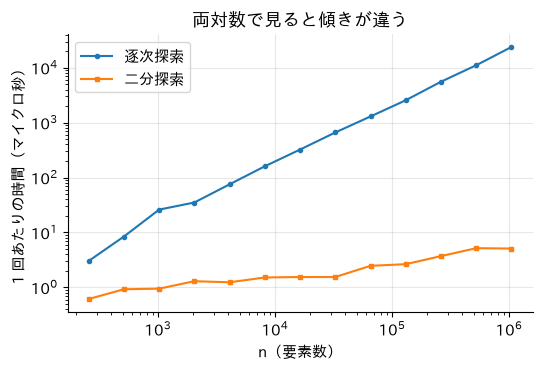

In [7]:
fig, ax = plt.subplots()
ax.loglog(sizes, [t * 1e6 for t in lin_times], marker="o", markersize=3,
          label="逐次探索")
ax.loglog(sizes, [t * 1e6 for t in bin_times], marker="s", markersize=3,
          label="二分探索")
ax.set_xlabel("n（要素数）")
ax.set_ylabel("1 回あたりの時間（マイクロ秒）")
ax.set_title("両対数で見ると傾きが違う")
ax.legend()
plt.show()

両対数の目盛では，$O(n)$ は傾き 1 の直線，$O(\log n)$ はほとんど平らになる。
**傾きがオーダーを表している。**

## 境界をひとつ書き違えると

二分探索は 7 行だが，正しく書くのは見かけより難しい。
$\mathit{lo} \leftarrow \mathit{mid} + 1$ を $\mathit{lo} \leftarrow \mathit{mid}$
と書いてしまった版を動かしてみる。

止まらなくなるので，回数に上限をつけておく。

In [8]:
def binary_search_bug(a, x, limit=50):
    """lo <- mid + 1 を lo <- mid と書き違えた版。"""
    lo, hi = 0, len(a) - 1
    steps = 0
    while lo <= hi:
        steps += 1
        if steps > limit:
            return "止まらない", steps
        mid = (lo + hi) // 2
        if a[mid] == x:
            return mid, steps
        elif a[mid] < x:
            lo = mid          # 本当は mid + 1
        else:
            hi = mid - 1
    return -1, steps


small = [10, 20, 30]
for x in (10, 20, 30, 25):
    print(f"x = {x:3d} -> {binary_search_bug(small, x)}")

x =  10 -> (0, 2)
x =  20 -> (1, 1)
x =  30 -> ('止まらない', 51)
x =  25 -> ('止まらない', 51)


先頭の 2 つは見つかるのに，**30 と 25 では止まらない**。
30 は配列の中にある値であることに注意してほしい。

$\mathit{lo} = 1$, $\mathit{hi} = 2$ になった時点を見る。
$\mathit{mid} = \lfloor 3/2 \rfloor = 1$ で，$a[1] = 20$ はどちらの $x$ より小さいから
$\mathit{lo} \leftarrow \mathit{mid} = 1$。**範囲がまったく狭まらない。**
同じ状態をくり返すだけになる。

こういう誤りは，いくつか試して動いたというだけでは見つからない。
だから **不変条件** から境界を決める，という話になるのであった。

> **不変条件** …… $x$ が $A$ の中にあるならば，
> その位置 $i$ は $\mathit{lo} \le i \le \mathit{hi}$ を満たす

$A[\mathit{mid}] < x$ なら，添字 $\mathit{mid}$ **以下** に $x$ はない。
だから捨ててよいのは $\mathit{mid}$ までで，
次の範囲の左端は $\mathit{mid} + 1$ でなければならない。
$\mathit{mid}$ のままにすると，捨てたはずの $\mathit{mid}$ が範囲に残り続ける。

## 整列しておく元は取れるか

二分探索には整列が要る。整列は $O(n \log n)$ で，1 回しか引かないなら損である。
では何回引けば元が取れるのか，実際に測ってみる。

In [9]:
n = 200_000
random.seed(1)
data = [random.randrange(10**9) for _ in range(n)]
keys = [random.choice(data) for _ in range(400)]


def plan_linear(k):
    """整列せず、逐次探索を k 回する。"""
    t0 = time.perf_counter()
    for x in keys[:k]:
        linear_search(data, x)
    return time.perf_counter() - t0


def plan_binary(k):
    """まず整列し、そのあと二分探索を k 回する。"""
    t0 = time.perf_counter()
    b = sorted(data)
    for x in keys[:k]:
        binary_search(b, x)
    return time.perf_counter() - t0


print(f"{'k（探索回数）':>14}{'逐次のみ (秒)':>16}{'整列+二分 (秒)':>16}")
for k in (1, 2, 5, 10, 50, 200, 400):
    print(f"{k:>14}{plan_linear(k):>16.3f}{plan_binary(k):>16.3f}")

       k（探索回数）        逐次のみ (秒)       整列+二分 (秒)
             1           0.001           0.048
             2           0.002           0.046


             5           0.013           0.049
            10           0.033           0.048


            50           0.220           0.048


           200           0.848           0.043


           400           1.523           0.043


$k$ が小さいうちは整列のぶんだけ損をしているが，
どこかで逆転して，あとは差が開く一方になる。

配布文書では比較の回数だけで見積もって「34 回ほどで元が取れる」とした。
実測の逆転点がそれとずれるのは，
**1 回の比較に付随する手間が，整列と探索で違う**からである。
オーダーの議論は目安であって，定数倍は測らないと分からない。

ただし **「何回引くかで最適な方法が変わる」という結論は変わらない。**

## Python の道具

### `in` は何をしているか

In [10]:
n = 200_000
lst = list(range(n))
st = set(lst)
target = n - 1          # いちばん後ろ。逐次探索には最悪

t0 = time.perf_counter()
for _ in range(100):
    target in lst       # list なら逐次探索。O(n)
t_list = time.perf_counter() - t0

t0 = time.perf_counter()
for _ in range(100):
    target in st        # set ならハッシュ表。平均 O(1)
t_set = time.perf_counter() - t0

print(f"list の in: {t_list * 1e3:8.2f} ms")
print(f"set  の in: {t_set * 1e3:8.4f} ms")
print(f"比: {t_list / t_set:,.0f} 倍")

list の in:   110.94 ms
set  の in:   0.0838 ms
比: 1,324 倍


見た目は同じ 2 文字の `in` だが，中でしていることが違う。
**選ぶ基準は書きやすさではなく計算量である。**

なお `list` の `in` は，中身が整列済みでも逐次探索である。
Python は並んでいることを知らないからである。

### `bisect`

整列済みの列に対する二分探索は標準ライブラリにある。

In [11]:
import bisect

a = [3, 7, 12, 18, 23, 29, 34, 41, 47, 52, 58, 63]

print("58 の位置:", bisect.bisect_left(a, 58))
print("50 を入れるなら:", bisect.bisect_left(a, 50))

# 見つかったかどうかは自分で確かめる
def contains(a, x):
    i = bisect.bisect_left(a, x)
    return i < len(a) and a[i] == x

print("58 はあるか:", contains(a, 58))
print("50 はあるか:", contains(a, 50))

bisect.insort(a, 50)        # 位置は O(log n)。挿入そのものは O(n)
print(a)

58 の位置: 10
50 を入れるなら: 9
58 はあるか: True
50 はあるか: False
[3, 7, 12, 18, 23, 29, 34, 41, 47, 50, 52, 58, 63]


`bisect_left` が返すのは「見つかった位置」ではなく
**「そこに入れても並びが崩れない位置」**である。
見つかったかどうかは自分で確かめる必要がある。

### $(lo + hi) / 2$ の桁あふれ

配布文書で触れた，Java の標準ライブラリに 10 年ひそんでいたバグである。

In [12]:
lo, hi = 2**30, 2**30 + 10

print("Python:", (lo + hi) // 2)              # 整数に上限がないので正しい

# 32 ビット符号付き整数を真似る
def as_int32(v):
    v &= 0xFFFFFFFF
    return v - 2**32 if v >= 2**31 else v

print("32 ビットだと:", as_int32(lo + hi) // 2)   # 負になる
print("安全な書き方:", lo + (hi - lo) // 2)

Python: 1073741829
32 ビットだと: -1073741819
安全な書き方: 1073741829


$\mathit{lo} + \lfloor (\mathit{hi} - \mathit{lo}) / 2 \rfloor$ と書けば
足し算が範囲を超えないので安全である。

Python では起きない問題だが，**言語の性質を知らないと正しさの議論が成り立たない**
という例である。

## まとめ

- 逐次探索の平均は $(n+1)/2$。実測とぴったり合うが，**オーダーは $O(n)$ のまま**
- 二分探索の最悪は $\lfloor \log_2 n \rfloor + 1$。$n = 100$ 万でも 20 回
- 両対数の図では，**傾きがオーダーを表す**
- 境界をひとつ書き違えると，見つかる値では動くのに失敗探索で止まらなくなる
- 整列の手間は，何回引くかで元が取れるかが決まる。逆転点は測らないと分からない
- `list` の `in` は $O(n)$，`set` の `in` は平均 $O(1)$。中でしていることが違う